# Movie Trend Analysis — IMDb 5000 Dataset

Exploratory data analysis (EDA) of ~5,000 movies from the Kaggle IMDb 5000 dataset using **Pandas**, **Matplotlib** and **Seaborn**.

**Goals**
1. Clean and prepare the raw data (nulls, duplicates, units, text noise).
2. Find the most profitable movies and the IMDb Top 250.
3. Identify the best directors, most popular genre combinations and critic vs. audience favourite actors.
4. Visualise trends in genre popularity, ratings, budgets and audience engagement.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

DATA_PATH = Path('data/Movie_Data.csv')
IMG_DIR = Path('images')
IMG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

## Task 1: Reading and Inspection

### Subtask 1.1: Import and read

In [2]:
movies = pd.read_csv(DATA_PATH)
movies.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,num_voted_users,cast_total_facebook_likes,actor_3_name,facenumber_in_poster,plot_keywords,movie_imdb_link,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,886204,4834,Wes Studi,0.0,avatar|future|marine|native|paraplegic,http://www.imdb.com/title/tt0499549/?ref_=fn_t...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,471220,48350,Jack Davenport,0.0,goddess|marriage ceremony|marriage proposal|pi...,http://www.imdb.com/title/tt0449088/?ref_=fn_t...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,Christoph Waltz,Spectre,275868,11700,Stephanie Sigman,1.0,bomb|espionage|sequel|spy|terrorist,http://www.imdb.com/title/tt2379713/?ref_=fn_t...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,Tom Hardy,The Dark Knight Rises,1144337,106759,Joseph Gordon-Levitt,0.0,deception|imprisonment|lawlessness|police offi...,http://www.imdb.com/title/tt1345836/?ref_=fn_t...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,Doug Walker,Star Wars: Episode VII - The Force Awakens ...,8,143,NaN,0.0,NaN,http://www.imdb.com/title/tt5289954/?ref_=fn_t...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


### Subtask 1.2: Inspect the dataframe

In [3]:
movies.info()
print('Shape:', movies.shape)
print('Total cells:', movies.size)

<class 'pandas.DataFrame'>
RangeIndex: 5043 entries, 0 to 5042
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      5024 non-null   str    
 1   director_name              4939 non-null   str    
 2   num_critic_for_reviews     4993 non-null   float64
 3   duration                   5028 non-null   float64
 4   director_facebook_likes    4939 non-null   float64
 5   actor_3_facebook_likes     5020 non-null   float64
 6   actor_2_name               5030 non-null   str    
 7   actor_1_facebook_likes     5036 non-null   float64
 8   gross                      4159 non-null   float64
 9   genres                     5043 non-null   str    
 10  actor_1_name               5036 non-null   str    
 11  movie_title                5043 non-null   str    
 12  num_voted_users            5043 non-null   int64  
 13  cast_total_facebook_likes  5043 non-null   int64  
 14  act

In [4]:
movies.describe().T

,count,mean,std,min,25%,50%,75%,max
num_critic_for_reviews,4993.0,1.401943e+02,1.216017e+02,1.00,50.00,110.00,195.00,8.130000e+02
duration,5028.0,1.072011e+02,2.519744e+01,7.00,93.00,103.00,118.00,5.110000e+02
director_facebook_likes,4939.0,6.865092e+02,2.813329e+03,0.00,7.00,49.00,194.50,2.300000e+04
actor_3_facebook_likes,5020.0,6.450098e+02,1.665042e+03,0.00,133.00,371.50,636.00,2.300000e+04
actor_1_facebook_likes,5036.0,6.560047e+03,1.502076e+04,0.00,614.00,988.00,11000.00,6.400000e+05
gross,4159.0,4.846841e+07,6.845299e+07,162.00,5340987.50,25517500.00,62309437.50,7.605058e+08
num_voted_users,5043.0,8.366816e+04,1.384853e+05,5.00,8593.50,34359.00,96309.00,1.689764e+06
cast_total_facebook_likes,5043.0,9.699064e+03,1.816380e+04,0.00,1411.00,3090.00,13756.50,6.567300e+05
facenumber_in_poster,5030.0,1.371173e+00,2.013576e+00,0.00,0.00,1.00,2.00,4.300000e+01
num_user_for_reviews,5022.0,2.727708e+02,3.779829e+02,1.00,65.00,156.00,326.00,5.060000e+03


## Task 2: Cleaning the Data

### Subtask 2.1: Inspect null values

In [5]:
null_summary = pd.DataFrame({
    'null_count': movies.isnull().sum(),
    'null_pct': (movies.isnull().mean() * 100).round(2)
}).sort_values('null_pct', ascending=False)
null_summary

,null_count,null_pct
gross,884,17.53
budget,492,9.76
aspect_ratio,329,6.52
content_rating,303,6.01
plot_keywords,153,3.03
title_year,108,2.14
director_facebook_likes,104,2.06
director_name,104,2.06
num_critic_for_reviews,50,0.99
actor_3_facebook_likes,23,0.46


In [6]:
row_nulls = movies.isnull().sum(axis=1)
print('Rows with at least one null:', (row_nulls > 0).sum())
row_nulls.value_counts().sort_index()

Rows with at least one null: 1288


0     3755
1      695
2      269
3      127
4       53
5       70
6       36
7       20
8       11
9        1
10       2
11       2
14       1
15       1
Name: count, dtype: int64

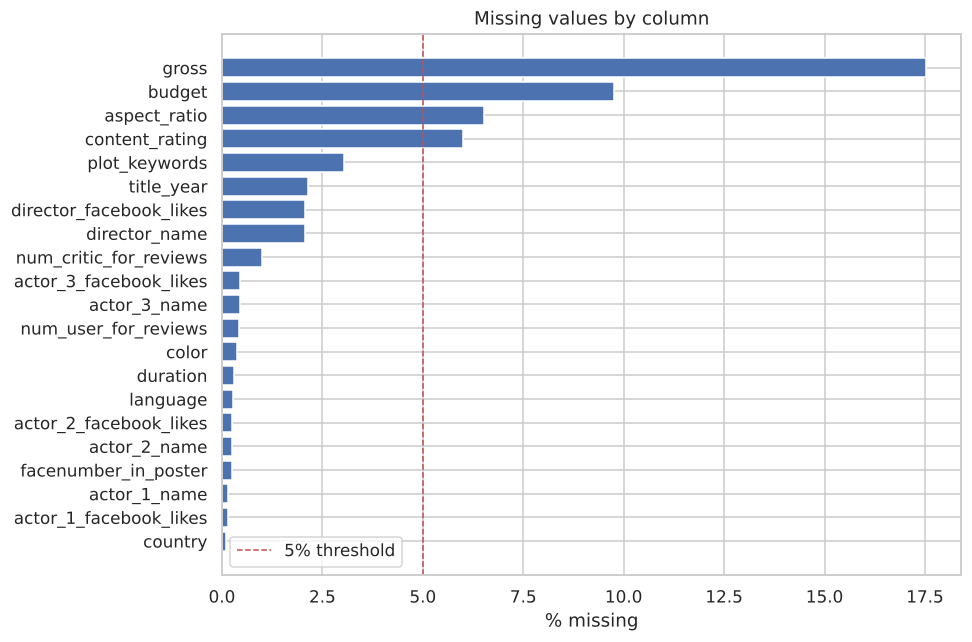

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
top_nulls = null_summary[null_summary.null_pct > 0]
ax.barh(top_nulls.index, top_nulls.null_pct, color='#4C72B0')
ax.invert_yaxis()
ax.axvline(5, color='#C44E52', ls='--', lw=1, label='5% threshold')
ax.set_xlabel('% missing'); ax.set_title('Missing values by column'); ax.legend()
save(fig, '01_missing_values')

### Subtask 2.2: Drop unnecessary columns

In [8]:
drop_cols = ['color', 'director_facebook_likes', 'actor_1_facebook_likes', 'actor_2_facebook_likes',
             'actor_3_facebook_likes', 'actor_2_name', 'cast_total_facebook_likes', 'actor_3_name',
             'duration', 'facenumber_in_poster', 'content_rating', 'country', 'movie_imdb_link',
             'aspect_ratio', 'plot_keywords']
movies = movies.drop(columns=drop_cols)
movies.shape

(5043, 13)

### Subtask 2.3: Drop rows with nulls in columns that are more than 5% null

In [9]:
null_pct = movies.isnull().mean() * 100
high_null_cols = null_pct[null_pct > 5].index.tolist()
print('Columns above 5% nulls:', high_null_cols)
movies = movies.dropna(subset=high_null_cols)
movies.shape

Columns above 5% nulls: ['gross', 'budget']


(3891, 13)

### Subtask 2.4: Drop rows with more than five NaN values

In [10]:
movies = movies[movies.isnull().sum(axis=1) <= 5]
movies.shape

(3891, 13)

### Subtask 2.5: Fill NaN values in `language`

In [11]:
movies['language'] = movies['language'].fillna('English')
movies['language'].isnull().sum()

np.int64(0)

### Extra cleaning: text noise
Movie titles in the raw file end with a non-breaking space (`\xa0`), which breaks matching and displays badly.

In [12]:
str_cols = movies.select_dtypes(include='object').columns
movies[str_cols] = movies[str_cols].apply(lambda s: s.str.replace('\xa0', ' ', regex=False).str.strip())
movies['movie_title'].head(3).tolist()

['Avatar', "Pirates of the Caribbean: At World's End", 'Spectre']

### Subtask 2.6: Rows retained

In [13]:
retained = len(movies)
print(f'Rows retained: {retained} of 5043 ({retained / 5043 * 100:.2f}%)')

Rows retained: 3891 of 5043 (77.16%)


**Checkpoint 1:** About 77% of the rows are retained.

## Task 3: Data Analysis

### Subtask 3.1: Convert `budget` and `gross` to million $

In [14]:
movies['budget'] = movies['budget'] / 1_000_000
movies['gross'] = movies['gross'] / 1_000_000
movies[['budget', 'gross']].describe().round(2)

,budget,gross
count,3891.00,3891.00
mean,45.21,51.05
std,222.39,69.80
min,0.00,0.00
25%,10.00,6.84
50%,24.00,27.98
75%,50.00,65.36
max,12215.50,760.51


> **Data-quality note:** the maximum budget (~$12,215M for *The Host*) is not a real dollar figure. Several non-English films record `budget` in their local currency (e.g. Korean won, Japanese yen) while `gross` is US box office in USD. These rows are kept so the assignment checkpoints stay comparable, but they distort profit for foreign films; a production analysis would convert currencies or analyse English-language films separately.

In [15]:
movies.nlargest(5, 'budget')[['movie_title', 'language', 'budget', 'gross']]

,movie_title,language,budget,gross
2988,The Host,Korean,12215.500000,2.201412
3859,Lady Vengeance,Korean,4200.000000,0.211667
3005,Fateless,Hungarian,2500.000000,0.195888
2323,Princess Mononoke,Japanese,2400.000000,2.298191
2334,Steamboy,Japanese,2127.519898,0.410388


### Subtask 3.2: Highest-profit movies

In [16]:
movies['profit'] = movies['gross'] - movies['budget']
movies = movies.sort_values('profit', ascending=False)
top10 = movies.head(10)
top10[['movie_title', 'director_name', 'title_year', 'budget', 'gross', 'profit']]

,movie_title,director_name,title_year,budget,gross,profit
0,Avatar,James Cameron,2009.0,237.0,760.505847,523.505847
29,Jurassic World,Colin Trevorrow,2015.0,150.0,652.177271,502.177271
26,Titanic,James Cameron,1997.0,200.0,658.672302,458.672302
3024,Star Wars: Episode IV - A New Hope,George Lucas,1977.0,11.0,460.935665,449.935665
3080,E.T. the Extra-Terrestrial,Steven Spielberg,1982.0,10.5,434.949459,424.449459
794,The Avengers,Joss Whedon,2012.0,220.0,623.279547,403.279547
17,The Avengers,Joss Whedon,2012.0,220.0,623.279547,403.279547
509,The Lion King,Roger Allers,1994.0,45.0,422.783777,377.783777
240,Star Wars: Episode I - The Phantom Menace,George Lucas,1999.0,115.0,474.544677,359.544677
66,The Dark Knight,Christopher Nolan,2008.0,185.0,533.316061,348.316061


### Subtask 3.3: Drop duplicates and repeat Subtask 3.2
The list above contains a duplicate title, so we remove exact duplicates and recompute.

In [17]:
print('Duplicates found:', movies.duplicated().sum())
movies = movies.drop_duplicates()
movies = movies.sort_values('profit', ascending=False)
top10 = movies.head(10).reset_index(drop=True)
top10[['movie_title', 'director_name', 'title_year', 'budget', 'gross', 'profit']]

Duplicates found: 35


,movie_title,director_name,title_year,budget,gross,profit
0,Avatar,James Cameron,2009.0,237.0,760.505847,523.505847
1,Jurassic World,Colin Trevorrow,2015.0,150.0,652.177271,502.177271
2,Titanic,James Cameron,1997.0,200.0,658.672302,458.672302
3,Star Wars: Episode IV - A New Hope,George Lucas,1977.0,11.0,460.935665,449.935665
4,E.T. the Extra-Terrestrial,Steven Spielberg,1982.0,10.5,434.949459,424.449459
5,The Avengers,Joss Whedon,2012.0,220.0,623.279547,403.279547
6,The Lion King,Roger Allers,1994.0,45.0,422.783777,377.783777
7,Star Wars: Episode I - The Phantom Menace,George Lucas,1999.0,115.0,474.544677,359.544677
8,The Dark Knight,Christopher Nolan,2008.0,185.0,533.316061,348.316061
9,The Hunger Games,Gary Ross,2012.0,78.0,407.999255,329.999255


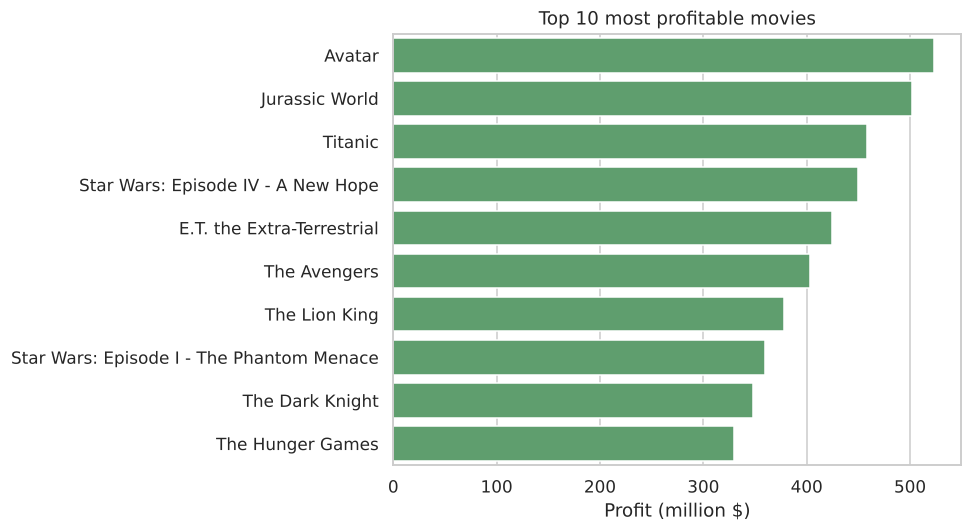

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top10, y='movie_title', x='profit', ax=ax, color='#55A868')
ax.set_xlabel('Profit (million $)'); ax.set_ylabel(''); ax.set_title('Top 10 most profitable movies')
save(fig, '02_top10_profit')

**Checkpoint 2:** Two movies directed by James Cameron (Avatar and Titanic) appear in the list.

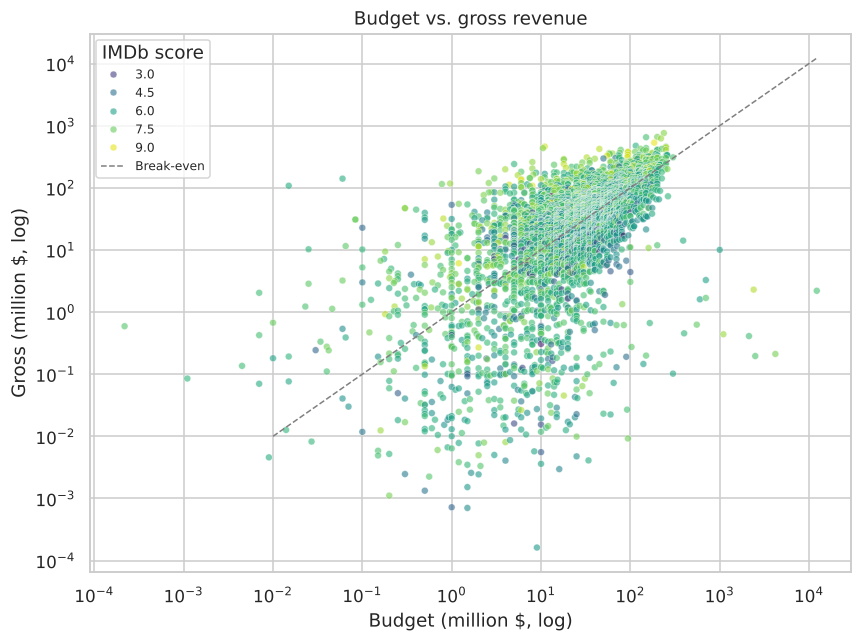

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_df = movies[(movies.budget > 0) & (movies.gross > 0)]
sns.scatterplot(data=plot_df, x='budget', y='gross', hue='imdb_score', palette='viridis',
                alpha=0.6, s=20, ax=ax)
lim = max(plot_df.budget.max(), plot_df.gross.max())
ax.plot([0.01, lim], [0.01, lim], ls='--', color='grey', lw=1, label='Break-even')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Budget (million $, log)'); ax.set_ylabel('Gross (million $, log)')
ax.set_title('Budget vs. gross revenue'); ax.legend(title='IMDb score', fontsize=8)
save(fig, '03_budget_vs_gross')

### Subtask 3.4: IMDb Top 250 (movies with more than 25,000 votes)

In [20]:
IMDb_Top_250 = (movies[movies['num_voted_users'] > 25000]
                .sort_values('imdb_score', ascending=False)
                .head(250)
                .reset_index(drop=True))
IMDb_Top_250.insert(0, 'Rank', range(1, len(IMDb_Top_250) + 1))
IMDb_Top_250[['Rank', 'movie_title', 'imdb_score', 'num_voted_users', 'language', 'title_year']].head(15)

,Rank,movie_title,imdb_score,num_voted_users,language,title_year
0,1,The Shawshank Redemption,9.3,1689764,English,1994.0
1,2,The Godfather,9.2,1155770,English,1972.0
2,3,The Godfather: Part II,9.0,790926,English,1974.0
3,4,The Dark Knight,9.0,1676169,English,2008.0
4,5,Schindler's List,8.9,865020,English,1993.0
5,6,The Lord of the Rings: The Return of the King,8.9,1215718,English,2003.0
6,7,Pulp Fiction,8.9,1324680,English,1994.0
7,8,"The Good, the Bad and the Ugly",8.9,503509,Italian,1966.0
8,9,The Lord of the Rings: The Fellowship of the Ring,8.8,1238746,English,2001.0
9,10,Inception,8.8,1468200,English,2010.0


In [21]:
Top_Foreign_Lang_Film = IMDb_Top_250[IMDb_Top_250['language'] != 'English']
print('Foreign-language films in Top 250:', len(Top_Foreign_Lang_Film))
Top_Foreign_Lang_Film[['Rank', 'movie_title', 'language', 'imdb_score']]

Foreign-language films in Top 250: 37


,Rank,movie_title,language,imdb_score
7,8,"The Good, the Bad and the Ugly",Italian,8.9
17,18,Seven Samurai,Japanese,8.7
18,19,City of God,Portuguese,8.7
22,23,Spirited Away,Japanese,8.6
30,31,Children of Heaven,Persian,8.5
39,40,The Lives of Others,German,8.5
51,52,Baahubali: The Beginning,Telugu,8.4
53,54,Das Boot,German,8.4
54,55,Amélie,French,8.4
57,58,Oldboy,Korean,8.4


In [22]:
'Veer-Zaara' in Top_Foreign_Lang_Film['movie_title'].values

True

**Checkpoint 3:** Veer-Zaara appears in the foreign-language list.

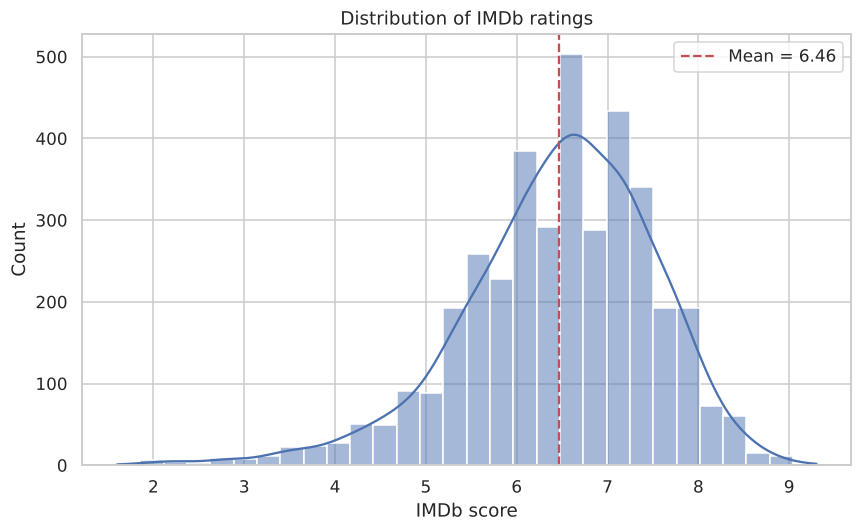

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(movies['imdb_score'], bins=30, kde=True, ax=ax, color='#4C72B0')
ax.axvline(movies['imdb_score'].mean(), color='#C44E52', ls='--', label=f"Mean = {movies['imdb_score'].mean():.2f}")
ax.set_xlabel('IMDb score'); ax.set_title('Distribution of IMDb ratings'); ax.legend()
save(fig, '04_imdb_score_distribution')

### Subtask 3.5: Best directors (highest mean IMDb score)

In [24]:
top10director = (movies.groupby('director_name')['imdb_score']
                 .mean()
                 .sort_values(ascending=False)
                 .head(10)
                 .round(2)
                 .to_frame())
top10director

,imdb_score
director_name,
Tony Kaye,8.60
Charles Chaplin,8.60
Majid Majidi,8.50
Damien Chazelle,8.50
Ron Fricke,8.50
Alfred Hitchcock,8.50
Sergio Leone,8.43
Christopher Nolan,8.43
S.S. Rajamouli,8.40


**Checkpoint 4:** Damien Chazelle (Whiplash, La La Land) is in the list.

A plain mean rewards directors with a single highly-rated film. As a robustness check, here are the top directors with **at least 5 films**:

In [25]:
director_stats = movies.groupby('director_name').agg(films=('movie_title', 'count'),
                                                   mean_score=('imdb_score', 'mean'))
director_stats[director_stats.films >= 5].sort_values('mean_score', ascending=False).head(10).round(2)

,films,mean_score
director_name,,
Christopher Nolan,8,8.43
Quentin Tarantino,8,8.20
James Cameron,7,7.91
Alejandro G. Iñárritu,5,7.84
David Fincher,10,7.75
Peter Jackson,12,7.68
Martin Scorsese,16,7.68
Francis Ford Coppola,9,7.66
Wes Anderson,7,7.63


### Subtask 3.6: Popular genre combinations

In [26]:
genre_split = movies['genres'].str.split('|')
movies['genre_1'] = genre_split.str[0]
movies['genre_2'] = genre_split.str[1].fillna(movies['genre_1'])
movies[['genres', 'genre_1', 'genre_2']].head()

,genres,genre_1,genre_2
0,Action|Adventure|Fantasy|Sci-Fi,Action,Adventure
29,Action|Adventure|Sci-Fi|Thriller,Action,Adventure
26,Drama|Romance,Drama,Romance
3024,Action|Adventure|Fantasy|Sci-Fi,Action,Adventure
3080,Family|Sci-Fi,Family,Sci-Fi


In [27]:
movies_by_segment = movies.groupby(['genre_1', 'genre_2'])
PopGenre = movies_by_segment['gross'].mean().sort_values(ascending=False).head(5).round(2).to_frame()
PopGenre

gross
genre_1   genre_2          
Family    Sci-Fi     434.95
Adventure Sci-Fi     228.63
          Family     118.92
          Animation  117.00
Action    Adventure  109.60

**Checkpoint 5:** Family + Sci-Fi is the highest-grossing genre combination on average.

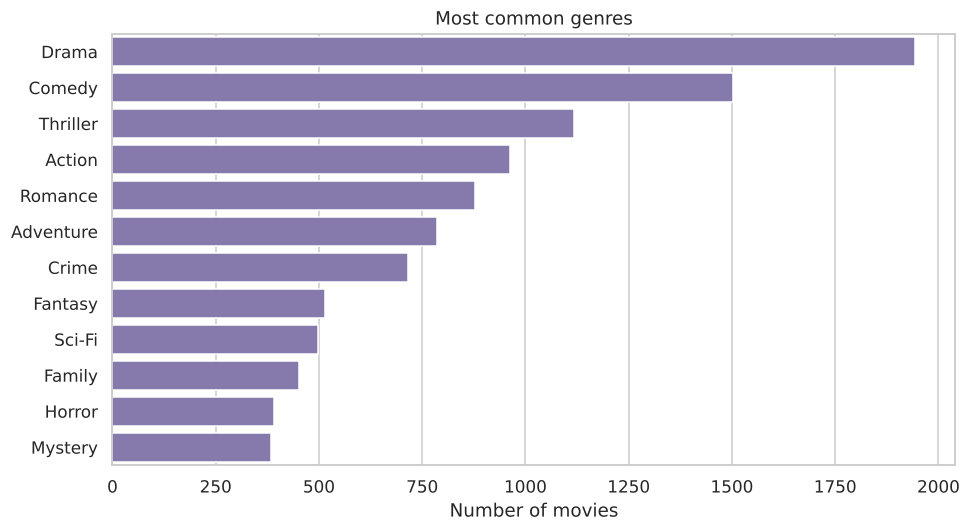

In [28]:
genre_counts = movies['genres'].str.split('|').explode().value_counts().head(12)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=genre_counts.values, y=genre_counts.index, ax=ax, color='#8172B3')
ax.set_xlabel('Number of movies'); ax.set_ylabel(''); ax.set_title('Most common genres')
save(fig, '05_genre_frequency')

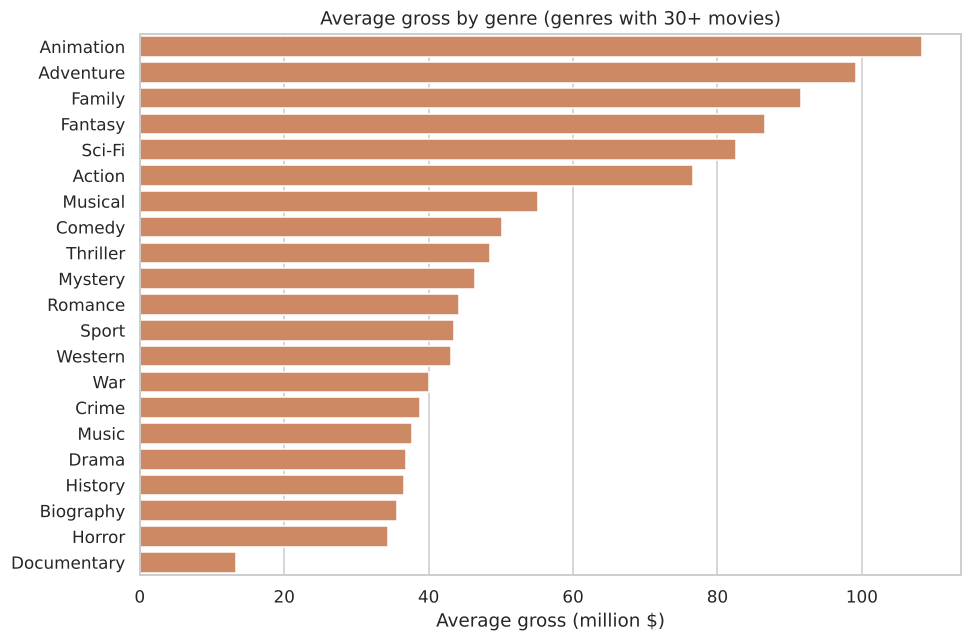

,movies,avg_gross,avg_score
genre,,,
Animation,199,108.36,6.70
Adventure,787,99.22,6.46
Family,451,91.56,6.21
Fantasy,514,86.54,6.29
Sci-Fi,497,82.58,6.32
Action,962,76.58,6.29
Musical,103,55.19,6.56
Comedy,1503,50.10,6.18
Thriller,1118,48.53,6.38


In [29]:
genre_perf = (movies.assign(genre=movies['genres'].str.split('|')).explode('genre')
              .groupby('genre').agg(movies=('movie_title', 'count'),
                                    avg_gross=('gross', 'mean'),
                                    avg_score=('imdb_score', 'mean'))
              .query('movies >= 30')
              .sort_values('avg_gross', ascending=False))
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=genre_perf.avg_gross, y=genre_perf.index, ax=ax, color='#DD8452')
ax.set_xlabel('Average gross (million $)'); ax.set_ylabel(''); ax.set_title('Average gross by genre (genres with 30+ movies)')
save(fig, '06_avg_gross_by_genre')
genre_perf.round(2)

### Subtask 3.7: Critic-favourite and audience-favourite actors

In [30]:
Meryl_Streep = movies[movies['actor_1_name'] == 'Meryl Streep']
Leo_Caprio = movies[movies['actor_1_name'] == 'Leonardo DiCaprio']
Brad_Pitt = movies[movies['actor_1_name'] == 'Brad Pitt']
print(len(Meryl_Streep), len(Leo_Caprio), len(Brad_Pitt))

11 21 17


In [31]:
Combined = pd.concat([Meryl_Streep, Leo_Caprio, Brad_Pitt])
Combined.shape

(49, 16)

In [32]:
actor_reviews = (Combined.groupby('actor_1_name')[['num_critic_for_reviews', 'num_user_for_reviews']]
                 .mean().round(1))
print('Critic favourite  :', actor_reviews['num_critic_for_reviews'].idxmax())
print('Audience favourite:', actor_reviews['num_user_for_reviews'].idxmax())
actor_reviews.sort_values('num_critic_for_reviews', ascending=False)

Critic favourite  : Leonardo DiCaprio
Audience favourite: Leonardo DiCaprio


,num_critic_for_reviews,num_user_for_reviews
actor_1_name,,
Leonardo DiCaprio,330.2,914.5
Brad Pitt,245.0,742.4
Meryl Streep,181.5,297.2


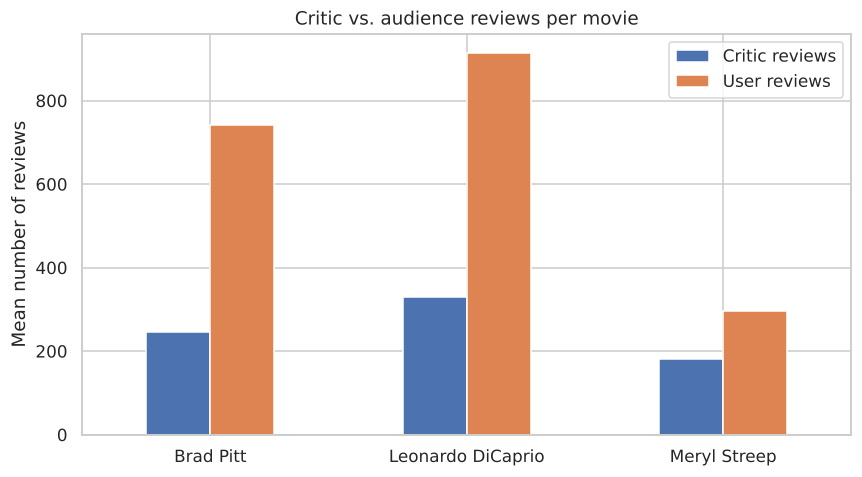

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.5))
actor_reviews.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'], rot=0)
ax.set_ylabel('Mean number of reviews'); ax.set_xlabel('')
ax.set_title('Critic vs. audience reviews per movie'); ax.legend(['Critic reviews', 'User reviews'])
save(fig, '07_actor_reviews')

**Checkpoint 6:** Leonardo DiCaprio leads both lists.

## Task 4: Additional Trend Analysis

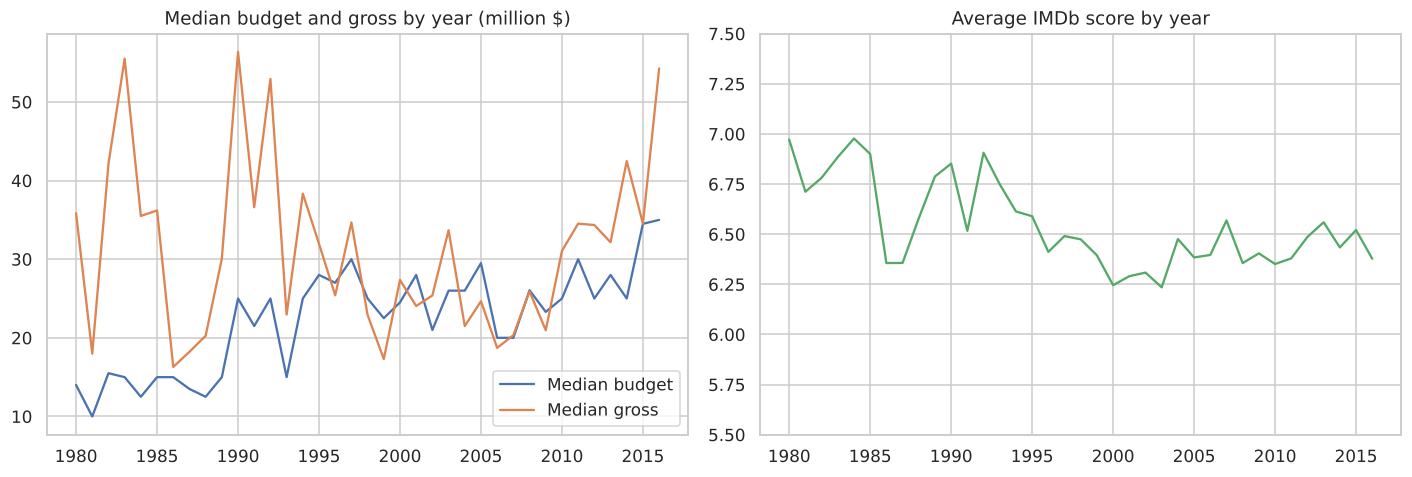

In [34]:
movies['decade'] = (movies['title_year'] // 10 * 10).astype('Int64')
yearly = (movies[movies.title_year >= 1980].groupby('title_year')
          .agg(movies=('movie_title', 'count'), avg_score=('imdb_score', 'mean'),
               avg_budget=('budget', 'median'), avg_gross=('gross', 'median')))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(yearly.index, yearly.avg_budget, label='Median budget')
axes[0].plot(yearly.index, yearly.avg_gross, label='Median gross')
axes[0].set_title('Median budget and gross by year (million $)'); axes[0].legend()
axes[1].plot(yearly.index, yearly.avg_score, color='#55A868')
axes[1].set_title('Average IMDb score by year'); axes[1].set_ylim(5.5, 7.5)
save(fig, '08_yearly_trends')

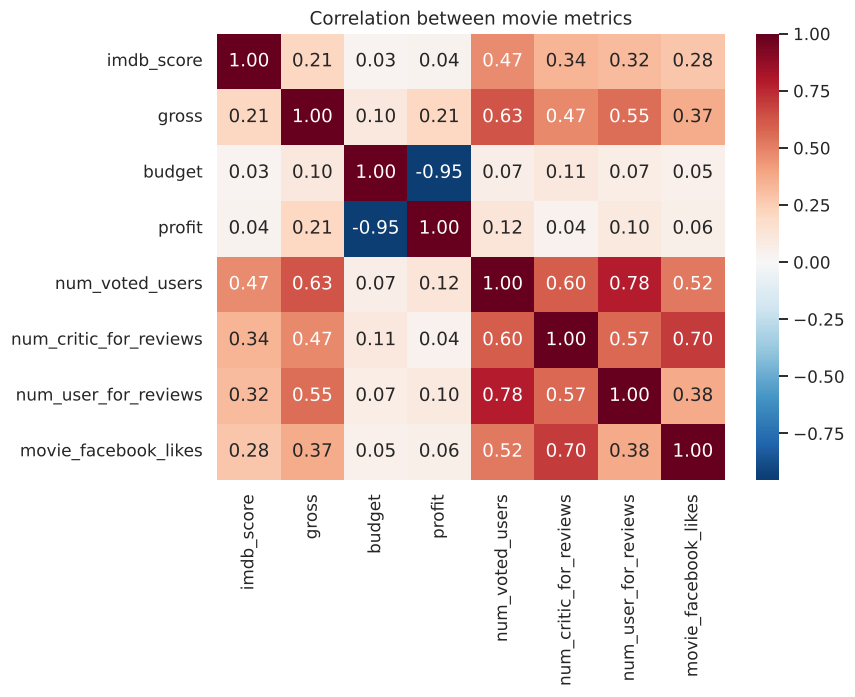

In [35]:
movies['roi'] = movies['profit'] / movies['budget']
corr_cols = ['imdb_score', 'gross', 'budget', 'profit', 'num_voted_users',
             'num_critic_for_reviews', 'num_user_for_reviews', 'movie_facebook_likes']
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(movies[corr_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation between movie metrics')
save(fig, '09_correlation_heatmap')

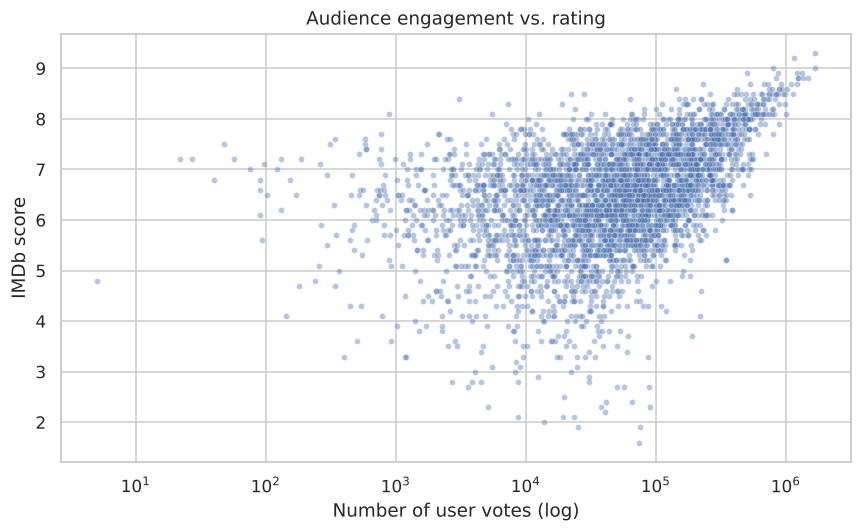

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=movies, x='num_voted_users', y='imdb_score', alpha=0.4, s=15, ax=ax)
ax.set_xscale('log'); ax.set_xlabel('Number of user votes (log)'); ax.set_ylabel('IMDb score')
ax.set_title('Audience engagement vs. rating')
save(fig, '10_votes_vs_score')

## Save the cleaned dataset

In [37]:
out = Path('data/movies_cleaned.csv')
movies.to_csv(out, index=False)
print(f'Saved {len(movies)} rows x {movies.shape[1]} columns to {out}')

Saved 3856 rows x 18 columns to data/movies_cleaned.csv


## Key Findings

1. **Data quality:** `gross` (17.5%) and `budget` (9.8%) had the most missing values; after cleaning and removing duplicates about 77% of the original rows remain.
2. **Profitability:** Avatar is the most profitable film; James Cameron directs two of the top 10. Budget and gross are positively correlated, but many low-budget films return far more than their cost.
3. **Ratings:** IMDb scores cluster around 6–7. The number of user votes correlates more strongly with rating than budget does, so audience engagement is a better signal of quality than spending.
4. **Genres:** Drama, Comedy and Thriller are the most common genres, while Animation, Adventure and Family earn the most per film. Family + Sci-Fi is the top-grossing genre pair on average.
5. **Directors:** Mean-score rankings favour directors with one standout film; requiring 5+ films surfaces consistently strong directors such as Christopher Nolan and Quentin Tarantino.
6. **Actors:** Leonardo DiCaprio draws the most critic and user reviews per film among the three actors compared.